# Hypothesis testing

## ANOVA

**AN**alysis **O**f **VA**riance (ANOVA) is a statistical method used to test whether there are statistically significant differences between the means of three or more groups. At a conceptual level, ANOVA compares two sources of variation.
1) **Between-group variation:** How different are the group means from the overall mean?

2) **Within-group variation:** How much do individual data points differ within each group?

Mathematically, this comparison is expressed through the F-statistic:

$$ F = \frac{\text{MS}_\text{between}}{\text{MS}_\text{within}}$$

where $MS_{between}$ and $MS_{within}$ represent the mean squares between and within groups, respectively. Each mean square is calculated by dividing its corresponding sum of squares by its degrees of freedom.

The F-statistic represents the ratio of between-group variation to within-group variation. A larger F-statistic indicates that the between-group variation is relatively large compared with the within-group variation. This provides stronger evidence that the group means are *not* all equal. The statistical significance of this evidence is subsequently assessed using the p-value. Conversely, a smaller F-statistic indicates that the between-group variation is relatively small compared with the within-group variation, providing less evidence against the null hypothesis. This is the fundamental premise of ANOVA.

The null hypothesis ($H_0$) for ANOVA states that all group means are equal. For instance, if we are comparing three groups with population means $\mu_1$, $\mu_2$, and $\mu_3$, the null hypothesis can be expressed as:

$$H_0: \mu_1 = \mu_2 = \mu_3$$

The alternative hypothesis ($H_1$) states that at least one group mean is different from the others.

$$H_1: \text{Not all group means are equal}$$

An important point to note is that the alternative hypothesis does not necessarily imply that all group means are different. It simply indicates that at least one pair of group means differs. Furthermore, ANOVA does not identify which specific group means are significantly different. It only determines whether there is sufficient statistical evidence to conclude that not all group means are equal. To identify which specific groups differ, additional statistical tests, known as *post hoc* tests, are required.

## Types of ANOVA
ANOVA can be broadly classified into two main types:

1) **One-way ANOVA:** Tests whether there are statistically significant differences between group means based on one independent variable (factor).
2) **Two-way ANOVA:** Examines the effects of two independent variables (factors) on the mean of a dependent variable. In addition to examining the individual effect of each factor, it can also determine whether there is an interaction effect between the two factors.

## One-way ANOVA

To learn how to perform ANOVA in R, we will use the data from the paper:

[Chemogenetic attenuation of neuronal activity in the entorhinal cortex reduces Aβ and tau pathology in the hippocampus](https://journals.plos.org/plosbiology/article?id=10.1371/journal.pbio.3000851)

The data is available in the supplementary materials of the paper (link).

Here, we’ll reproduce the results from Figure 3c of the manuscript.

The data for Figure 3 is in the sheet 3 of the Excel file. We’ll skip the first row which just contains some header information. Also we need data from the first six columns (A-F). To read the excel file we’ll use `read_excel` function from the `readxl` package.

After creating a dataframe `LH_gamma`, we will convert the `Genotype` column to a factor since this will be required for the subsequent ANOVA analysis.

In [1]:
#| warning: false
#| include: false
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


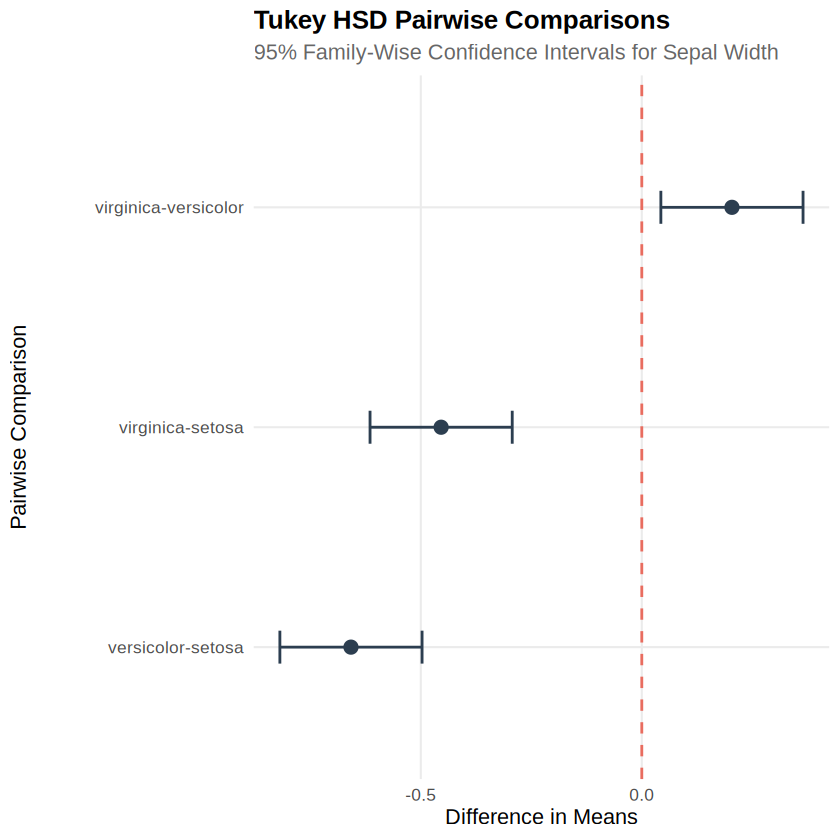

In [ ]:
library(ggplot2)
library(dplyr)
library(tibble)

# 1. Run ANOVA and Tukey HSD
model <- aov(Sepal.Width ~ Species, data = iris)
tukey_res <- TukeyHSD(model)

# 2. Convert the Tukey matrix into a clean data frame
tukey_df <- as.data.frame(tukey_res$Species) %>%
  rownames_to_column("comparison")

# 3. Create the ggplot2 visualization
ggplot(tukey_df, aes(x = comparison, y = diff)) +
  # Add the point estimate for the difference in means
  geom_point(size = 3.5, color = "#2c3e50") +
  # Add the 95% confidence interval error bars
  geom_errorbar(aes(ymin = lwr, ymax = upr), width = 0.15, color = "#2c3e50", linewidth = 0.8) +
  # Add a dashed red reference line at zero (no difference)
  geom_hline(yintercept = 0, linetype = "dashed", color = "#e74c3c", linewidth = 0.8, alpha = 0.8) +
  # Flip coordinates so category names are easy to read on the y-axis
  coord_flip() +
  # Clean academic styling and labels
  labs(
    title = "Tukey HSD Pairwise Comparisons",
    subtitle = "95% Family-Wise Confidence Intervals for Sepal Width",
    x = "Pairwise Comparison",
    y = "Difference in Means"
  ) +
  theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0),
    plot.subtitle = element_text(color = "gray40", hjust = 0),
    panel.grid.minor = element_blank()
  )

In [ ]:
#| include: false
install.packages("multcomp")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘zoo’, ‘mvtnorm’, ‘TH.data’, ‘sandwich’




In [ ]:
#| warning: false
#| message: false
library(readxl)
library(tidyverse)
library(multcomp)

LH_gamma <- read_excel("plos_bio1.xlsx", sheet=3, range="A2:F39")

LH_gamma_2 <- LH_gamma %>%
  mutate(Genotype = factor(Genotype, levels = c("Control", "EC-Tau", "hAPP", "EC-Tau/hAPP")))
head(LH_gamma)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: mvtnorm

Loading required package: survival

Loading required package: TH.data

Loading required package: MASS


Attaching package: ‘MASS’


The following object is masked from ‘package:dplyr’:

    select



Attaching package: ‘TH.data’


The following object is masked from ‘package:MASS’:

    geyser




Mouse ID,Genotype,Sex,Theta (4-12 Hz) %,Low Gamma (35-55 Hz) %,High Gamma (65-120 Hz) %
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
250704a2,Control,Male,59.56905,5.049760,5.4189129999999999
270704a3,Control,Male,34.02242,9.374330,5.4359440000000001
60704a4,Control,Male,47.09975,9.050000,5.8367961529999999
60704a5,Control,Male,30.06438,6.963757,5.8191324069999997
270704-3,Control,Female,39.36074,8.228760,8.3063029999999998
430704-1,Control,Female,64.24069,4.838260,6.6968300000000003


To perform ANOVA, we will use the aov function. For our analysis we want to test the null hypothesis that the means of the four Genotypes are equal. The independent varialbe is Theta (4-12 Hz) % and the dependent variable is Genotype. So, the formula for the ANOVA is: `Theta (4-12 Hz) % ~ Genotype`

Next, we will use the `glht` function from the `multcomp` package to perform post-hoc analysis. `glht` stands for “general linear hypothesis test”. The `glht` function takes the ANOVA results and the type of post-hoc test as arguments. In our case, we will use Dunnett’s test to compare each group with the control group. The `mcp` function is used to specify the type of comparison.

By default the first group is considered as the control group. If you want to change the control group, you can use the `control` argument in the `mcp` function.



In [ ]:
anova_results <- aov(`Theta (4-12 Hz) %` ~ Genotype, data=LH_gamma_2)
dunnett_results <- glht(anova_results, linfct = mcp(Genotype = "Dunnett"))
summary_dunnett <- summary(dunnett_results)
summary_dunnett


	 Simultaneous Tests for General Linear Hypotheses

Multiple Comparisons of Means: Dunnett Contrasts


Fit: aov(formula = `Theta (4-12 Hz) %` ~ Genotype, data = LH_gamma_2)

Linear Hypotheses:
                           Estimate Std. Error t value Pr(>|t|)   
EC-Tau - Control == 0        -7.128      6.176  -1.154  0.52352   
hAPP - Control == 0         -15.961      5.840  -2.733  0.02679 * 
EC-Tau/hAPP - Control == 0  -19.185      5.840  -3.285  0.00669 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
(Adjusted p values reported -- single-step method)


### Preparing the data for plotting

Based on the p-values for the pairwise comparison, a stars variable is created to hold the significance level of each comparison. The cut function is used to create a categorical variable based on the p-values stored in the `p_values` variable. The `breaks` argument specifies the cut points for the categories, and the `labels` argument specifies the labels for each category.

The names for the pair of groups being compared are stored in the `pair_names` variable. These names can be accessed using the `names` function on the `summary_dunnett$test$tstat` object.

The `LH_gamma_summary` dataframe is created using the `group_by` and `summarise` functions from the `dplyr` package. The `mean_theta` and `sem_theta` (standard error of the mean) are calculated for each Genotype group.


In [ ]:
# 1. Capture the printed console text of the summary
summary_lines <- capture.output(summary(summary_dunnett))

# 2. Filter only the lines that contain the linear hypotheses (identified by '== 0')
hypothesis_lines <- grep("== 0", summary_lines, value = TRUE)

# 3. Extract the final token of each line (either the significance star or the p-value)
extracted_symbols <- sapply(hypothesis_lines, function(line) {
  tokens <- strsplit(trimws(line), "\\s+")[[1]]
  last_token <- tail(tokens, 1)

  # If the last token is a number, there is no star -> map it to "ns"
  if (grepl("^[0-9.]+$", last_token)) {
    return("ns")
  } else {
    return(last_token) # Returns "*", "**", or "***"
  }
})

# Clean up the vector names
names(extracted_symbols) <- NULL

# View the result
print(extracted_symbols)

[1] "ns" "*"  "**"


In [ ]:
p_values <- summary_dunnett$test$pvalues
stars <- cut(p_values,
             breaks = c(-Inf, 0.001, 0.01, 0.05, 1),
             labels = c("***", "**", "*", "ns"))

LH_gamma_summary <- LH_gamma %>%
  group_by(Genotype) %>%
  summarize(
    mean_theta = mean(`Theta (4-12 Hz) %`, na.rm = TRUE),
    sem_theta = sd(`Theta (4-12 Hz) %`, na.rm = TRUE) / sqrt(n())
  )
LH_gamma_summary

Genotype,mean_theta,sem_theta
<chr>,<dbl>,<dbl>
Control,42.40957,5.480056
EC-Tau,35.28125,5.472521
EC-Tau/hAPP,23.22467,3.082346
hAPP,26.44856,2.658695


### Plotting

To re-create the Figure 3c from the paper, we’ll use ggplot2 to create multiple geometric layers. The first layer is a bar plot with error bars. The `geom_bar` function is used to create the bars, and the `geom_errorbar` function is used to add error bars. The `geom_jitter` function is used to add individual data points to the plot. The `geom_text` function is used to add the mean values on the bars.

To show the statistical significance, we will use the `geom_text` function to add asterisks to the plot. The `geom_segment` function is used to draw lines between the groups being compared.

Finally, the plot is customized using the theme function to adjust the appearance of the plot. The `scale_fill_manual` function is used to set the colors for each Genotype group.

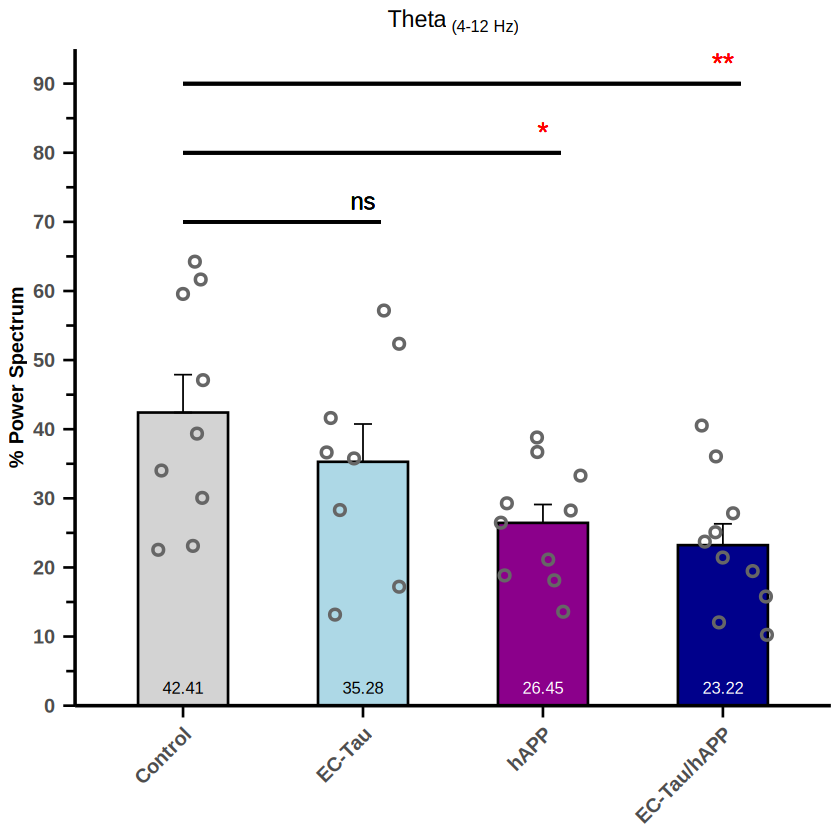

In [ ]:
ggplot(LH_gamma_summary, aes(x = reorder(Genotype, mean_theta, FUN = mean, decreasing = TRUE),
                             y = mean_theta, fill = Genotype)) +
  geom_bar(stat = "identity", color = "black", width = 0.5, linewidth = 0.75, position = "dodge") +
  geom_errorbar(aes(ymin = mean_theta, ymax = mean_theta + sem_theta), width = 0.1) +
  geom_jitter(data = LH_gamma, aes(x = Genotype, y = `Theta (4-12 Hz) %`),
              width = 0.25, height = 0, size = 2, shape = 1, stroke=1.5, color="#666666") +
  # show means on bars
  geom_text(aes(label = round(mean_theta, 2), y = 0), size = 3.5, vjust = -1,
            color = rep(c("black", "white"), each = 2)) +
  geom_text(aes(x=2,y=73,label = stars[1]), size = 5, color="black") +
  geom_segment(aes(x=1, xend=2.10, y=70, yend=70), color="black", linewidth =1) +
  geom_text(aes(x=3,y=83,label = stars[2]), size = 6, color="red") +
  geom_segment(aes(x=1, xend=3.10, y=80, yend=80), color="black", linewidth=1) +
  geom_text(aes(x=4,y=93,label = stars[3]), size = 6, color="red") +
  geom_segment(aes(x=1, xend=4.10, y=90, yend=90), color="black", linewidth=1) +
  scale_fill_manual(values = c("Control" = "lightgrey", "EC-Tau" = "lightblue", "hAPP"="darkmagenta", "EC-Tau/hAPP" = "darkblue")) +
  scale_y_continuous(breaks = seq(0, 90, by = 10), limits = c(0, 95),
                     expand = c(0,0),
                     minor_breaks = seq(0, 90, by = 5)) +
  theme_minimal() +
  guides(y=guide_axis(minor.ticks = TRUE)) +
  ylab("% Power Spectrum") +
  ggtitle(expression("Theta" [" (4-12 Hz)"])) +
  theme(axis.title.x = element_blank(),
        axis.title.y = element_text(size = 12, face = "bold"),
        axis.text.x = element_text(angle = 45, hjust = 1),
        axis.text = element_text(size = 12, face = "bold"),
        axis.ticks = element_line(linewidth = 0.75),
        axis.ticks.length = unit(0.25, "cm"),
        axis.line = element_line(linewidth = 1),
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        legend.position = "none",
        plot.title = element_text(hjust=0.5, size = 14, face = "bold"))
#ggsave("LH_gamma.png", width=4, height=5, dpi=300, bg="white")

### Tukey test

In [ ]:
library(multcomp)

# 1. Your existing model (assuming it's already fitted)
anova_results <- aov(`Theta (4-12 Hz) %` ~ Genotype, data = LH_gamma_2)

# 2. Change "Dunnett" to "Tukey"
tukey_glht <- glht(anova_results, linfct = mcp(Genotype = "Tukey"))

# 3. View the summary of all pairwise comparisons
summary_tukey <- summary(tukey_glht)
summary_tukey


	 Simultaneous Tests for General Linear Hypotheses

Multiple Comparisons of Means: Tukey Contrasts


Fit: aov(formula = `Theta (4-12 Hz) %` ~ Genotype, data = LH_gamma_2)

Linear Hypotheses:
                           Estimate Std. Error t value Pr(>|t|)  
EC-Tau - Control == 0        -7.128      6.176  -1.154   0.6590  
hAPP - Control == 0         -15.961      5.840  -2.733   0.0469 *
EC-Tau/hAPP - Control == 0  -19.185      5.840  -3.285   0.0122 *
hAPP - EC-Tau == 0           -8.833      6.029  -1.465   0.4691  
EC-Tau/hAPP - EC-Tau == 0   -12.057      6.029  -2.000   0.2084  
EC-Tau/hAPP - hAPP == 0      -3.224      5.684  -0.567   0.9411  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
(Adjusted p values reported -- single-step method)


In [ ]:
library(dplyr)
library(multcomp)

# 1. Filter out the control group (make sure "Control" matches your exact label)
LH_gamma_treatment_only <- LH_gamma_2 %>%
  filter(Genotype != "Control") %>%
  droplevels() # Drops "Control" from the factor levels so R doesn't look for it

# 2. Fit a new ANOVA model on just the treatment groups
anova_treatments_only <- aov(`Theta (4-12 Hz) %` ~ Genotype, data = LH_gamma_treatment_only)

# 3. Run Tukey's test using multcomp
tukey_treatments <- glht(anova_treatments_only, linfct = mcp(Genotype = "Tukey"))
summary(tukey_treatments)

# (Alternatively, you could use base R: TukeyHSD(anova_treatments_only))


	 Simultaneous Tests for General Linear Hypotheses

Multiple Comparisons of Means: Tukey Contrasts


Fit: aov(formula = `Theta (4-12 Hz) %` ~ Genotype, data = LH_gamma_treatment_only)

Linear Hypotheses:
                          Estimate Std. Error t value Pr(>|t|)  
hAPP - EC-Tau == 0          -8.833      5.340  -1.654   0.2422  
EC-Tau/hAPP - EC-Tau == 0  -12.057      5.340  -2.258   0.0807 .
EC-Tau/hAPP - hAPP == 0     -3.224      5.035  -0.640   0.7993  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
(Adjusted p values reported -- single-step method)


In [ ]:
#| include: false
# Create binary/factor columns based on your Genotype names
LH_gamma_2 <- LH_gamma_2 %>%
  mutate(
    # Check if "EC-Tau" is part of the genotype name
    EC_Tau = if_else(grepl("EC-Tau", Genotype), "Present", "Absent"),
    # Check if "hAPP" is part of the genotype name
    hAPP   = if_else(grepl("hAPP", Genotype), "Present", "Absent")
  )

# Convert them to factors so R treats them correctly for ANOVA
LH_gamma_2$EC_Tau <- factor(LH_gamma_2$EC_Tau, levels = c("Absent", "Present"))
LH_gamma_2$hAPP   <- factor(LH_gamma_2$hAPP, levels = c("Absent", "Present"))

In [ ]:
#| include: false
install.packages("car")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’


Warning message in install.packages("car"):
“installation of package ‘lme4’ had non-zero exit status”
Warning message in install.packages("car"):
“installation of package ‘pbkrtest’ had non-zero exit status”
Warning message in install.packages("car"):
“installation of package ‘car’ had non-zero exit status”


In [ ]:
#| include: false
library(car)
factorial_model <- lm(`Theta (4-12 Hz) %` ~ EC_Tau * hAPP, data = LH_gamma_2)

# Run Type III ANOVA
Anova(factorial_model, type = "III")

ERROR: Error in library(car): there is no package called ‘car’


In [ ]:
#| include: false
# 1. Set contrasts to sum-to-zero (essential for Type III equivalent testing)
options(contrasts = c("contr.sum", "contr.poly"))

# 2. Fit your linear model with the interaction term
factorial_model <- lm(`Theta (4-12 Hz) %` ~ EC_Tau * hAPP, data = LH_gamma_2)

# 3. Run drop1 with an F-test (this gives you your Type III ANOVA table)
drop1(factorial_model, test = "F")

# (Optional) Reset your contrasts back to default afterward if you prefer:
# options(contrasts = c("contr.treatment", "contr.poly"))

,Df,Sum of Sq,RSS,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,NA,5330.604,191.9012,NA,NA
EC_Tau:hAPP,1,34.95562,5365.560,190.1430,0.2163986,0.6448531


In [ ]:
#| include: false
options(contrasts = c("contr.treatment", "contr.poly"))
# 1. Fit the additive model (using '+' instead of '*')
additive_model <- lm(`Theta (4-12 Hz) %` ~ EC_Tau + hAPP, data = LH_gamma_2)

# 2. Run drop1 to test the main effects of each factor independently
drop1(additive_model, test = "F")

,Df,Sum of Sq,RSS,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,NA,5365.560,190.1430,NA,NA
EC_Tau,1,232.2189,5597.779,189.7107,1.471504,0.233469367
hAPP,1,1817.8228,7183.383,198.9385,11.519017,0.001765246


## Two-way ANOVA

[PLoS Biology Article](https://doi.org/10.1371/journal.pbio.3004073)

[Supplementary data](https://doi.org/10.48420/33103394)


In [3]:
#| include: false
install.packages("emmeans")
install.packages("ggh4x")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



To load the data, we'll read the excel file using the `read_excel()` function from the `readxl` library. Since the first row is column names, we'll skip that and instead give custom column names using the `col_names` keyword argument.

In [2]:
library(readxl)

df <- read_excel("PBIO_FigureS2.xlsx", col_names = c("Sample", "pi_neg"), skip = 1)
head(df)

Sample,pi_neg
<chr>,<dbl>
210308_Iso AF700 CD14_004.fcs,99.5
210308_UT-2d_CD14_1_038.fcs,90.3
210308_UT-2d_CD14_2_039.fcs,91.4
210308_UT-2d_CD14_3_040.fcs,91.8
210308_UT-2d_CD14_4_041.fcs,90.9
210308_UT-3d_CD14_1_102.fcs,90.2


Next, to facilitate data visualization, let's add two new columns to the dataframe having data for pma concentration and time regimen. These data will be generated by parsing the filenames using the functions from `stringr` library.

In [4]:
dose_levels <- c("UT", "10", "50", "100")
df <- df |>
  mutate(
    cond_regimen = str_split_i(Sample, "_", 2),
    is_iso       = str_starts(cond_regimen, fixed("Iso")),
    pma_conc     = factor(
      if_else(is_iso, NA_character_, str_split_i(cond_regimen, "-", 1)),
      levels = dose_levels
    ),
    regimen      = factor(
      if_else(is_iso, NA_character_, str_split_i(cond_regimen, "-", 2)),
      levels = c("2d", "3d")
    )
  ) |>
  select(-cond_regimen, -is_iso)
head(df)

Sample,pi_neg,pma_conc,regimen
<chr>,<dbl>,<fct>,<fct>
210308_Iso AF700 CD14_004.fcs,99.5,NA,NA
210308_UT-2d_CD14_1_038.fcs,90.3,UT,2d
210308_UT-2d_CD14_2_039.fcs,91.4,UT,2d
210308_UT-2d_CD14_3_040.fcs,91.8,UT,2d
210308_UT-2d_CD14_4_041.fcs,90.9,UT,2d
210308_UT-3d_CD14_1_102.fcs,90.2,UT,3d


Below, we create a dataframe having descriptive statistics.

In [6]:
library(dplyr)

df <- df %>%
  slice(-c(1, (n() - 1):n()))

# Summaries
summary_df <- df %>%
  group_by(pma_conc, regimen, .drop = FALSE) %>%
  summarise(
    mean_pi = mean(pi_neg),
    sd_pi   = sd(pi_neg),
    top_y   = max(pi_neg),
    .groups = "drop"
  ) %>%
  mutate(
    pma_conc = factor(as.character(pma_conc), levels = dose_levels),
    regimen  = factor(as.character(regimen), levels = c("2d", "3d"))
  )
summary_df

pma_conc,regimen,mean_pi,sd_pi,top_y
<fct>,<fct>,<dbl>,<dbl>,<dbl>
UT,2d,91.36667,0.4509250,91.8
UT,3d,90.82500,0.4349329,91.2
10,2d,86.77500,1.6255768,89.0
10,3d,56.70000,4.8969378,60.5
50,2d,57.00000,2.2181073,59.1
50,3d,33.92500,1.8373441,35.7
100,2d,36.05000,2.1977261,38.5
100,3d,41.00000,1.6970563,42.2


### Run ANOVA

Now that we have all the data in the required format, it is time to run a two-way ANOVA using the base R `aov()` function. Notice that `pi_neg ~ pma_conc * regimen` expands to `pi_neg ~ pma_conc + regimen + pma_conc:regimen`, which tests three different null hypotheses:

1) $$H_{0,1}: \mu_{\text{UT}} = \mu_{10} = \mu_{50} = \mu_{100}$$

   PMA dose has no overall effect on cell viability (`pi_neg`) averaged across regimens, where $\mu_{\text{dose}} = \frac{\mu_{\text{dose, 2d}} + \mu_{\text{dose, 3d}}}{2}$.

2) $$H_{0,2}: \mu_{\text{2d}} = \mu_{\text{3d}}$$

   Treatment duration/schedule (`2d` vs. `3d`) has no overall effect on cell viability averaged across doses, where $\mu_{r} = \frac{\mu_{\text{UT}, r} + \mu_{10, r} + \mu_{50, r} + \mu_{100, r}}{4}$ for each regimen $r \in \{\text{2d}, \text{3d}\}$.

3) $$H_{0,3}: (\mu_{d, \text{2d}} - \mu_{\text{UT}, \text{2d}}) = (\mu_{d, \text{3d}} - \mu_{\text{UT}, \text{3d}}) \quad \text{for all doses } d$$

   The dose-response curves for `2d` and `3d` are parallel; changing the regimen does not alter how cells respond to increasing PMA doses.

In the subsequent `emmeans(model, ~ pma_conc | regimen)` step, estimated marginal means for `pma_conc` are evaluated within each regimen (`2d` and `3d`) separately. This is important because the effect of PMA dose depends on the regimen. Finally, `contrast(emm, method = "trt.vs.ctrl1", adjust = "dunnett")` tests each dose against the `UT` control within each regimen with Dunnett multiplicity adjustment.

In [8]:
#| warning: false
#| message: false
library(emmeans)

# Dunnett post-hoc vs. UT within each regimen
model <- aov(pi_neg ~ pma_conc * regimen, data = df)
emm   <- emmeans(model, ~ pma_conc | regimen)
dunnett_df <- as.data.frame(contrast(emm, method = "trt.vs.ctrl1", adjust = "dunnett")) %>%
  mutate(
    pma_conc = factor(sub(" - UT$", "", contrast), levels = dose_levels),
    regimen  = factor(as.character(regimen), levels = c("2d", "3d")),
    stars = case_when(
      p.value < 0.001 ~ "***",
      p.value < 0.01  ~ "**",
      p.value < 0.05  ~ "*",
      TRUE            ~ "ns"
    )
  )
dunnett_df

,contrast,regimen,estimate,SE,df,t.ratio,p.value,pma_conc,stars
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
1,10 - UT,2d,-4.591667,1.849168,21,-2.483099,5.707781e-02,10,ns
2,50 - UT,2d,-34.366667,1.849168,21,-18.584937,7.505108e-14,50,***
3,100 - UT,2d,-55.316667,1.849168,21,-29.914359,2.908784e-14,100,***
4,10 - UT,3d,-34.125000,1.711997,21,-19.932866,3.985701e-14,10,***
5,50 - UT,3d,-56.900000,1.711997,21,-33.236046,2.908784e-14,50,***
6,100 - UT,3d,-49.825000,2.096759,21,-23.762863,2.953193e-14,100,***


### Create annotations

To create a data frame that we can use directly for plotting significance labels, we join `summary_df` and `dunnett_df` by `pma_conc` and `regimen`, then filter out the `UT` control and non-significant comparisons (`stars != "ns"`). Finally, we add `y_pos` to set the vertical position of each significance label above the data.

In [9]:
annot_df <- summary_df %>%
  left_join(dunnett_df, by = c("pma_conc", "regimen")) %>%
  filter(pma_conc != "UT", stars != "ns") %>%
  mutate(
    pma_conc = factor(as.character(pma_conc), levels = dose_levels),
    y_pos = pmax(mean_pi + sd_pi, top_y) + 3.5
  )
annot_df

pma_conc,regimen,mean_pi,sd_pi,top_y,contrast,estimate,SE,df,t.ratio,p.value,stars,y_pos
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
10,3d,56.700,4.896938,60.5,10 - UT,-34.12500,1.711997,21,-19.93287,3.985701e-14,***,65.09694
50,2d,57.000,2.218107,59.1,50 - UT,-34.36667,1.849168,21,-18.58494,7.505108e-14,***,62.71811
50,3d,33.925,1.837344,35.7,50 - UT,-56.90000,1.711997,21,-33.23605,2.908784e-14,***,39.26234
100,2d,36.050,2.197726,38.5,100 - UT,-55.31667,1.849168,21,-29.91436,2.908784e-14,***,42.00000
100,3d,41.000,1.697056,42.2,100 - UT,-49.82500,2.096759,21,-23.76286,2.953193e-14,***,46.19706


### Plotting

To recreate the published figure, we create a bar plot with error bars and scatter points, annotated with the significance labels calculated above. Note that We use `facet_grid2` from the `ggh4x` package for finer x-axis control across panels.

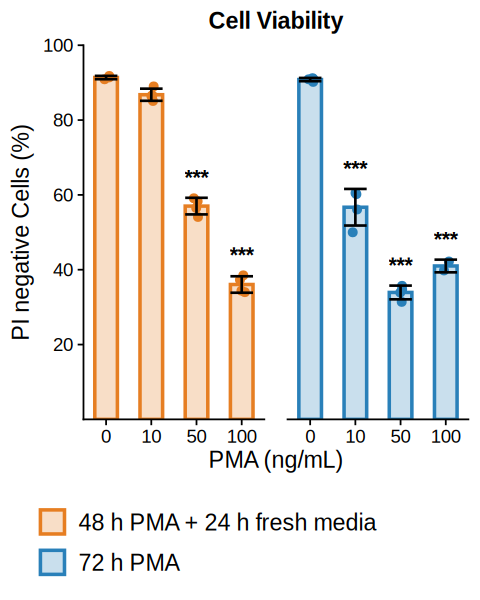

In [10]:
library(ggplot2)
library(ggh4x)

p_faceted <- ggplot() +
  geom_col(
    data = summary_df,
    aes(x = pma_conc, y = mean_pi, fill = regimen, color = regimen),
    width = 0.5,
    linewidth = 1,
    alpha = 0.25
  ) +
  geom_jitter(
    data = df,
    aes(x = pma_conc, y = pi_neg, color=regimen, fill=regimen),
    position = position_jitter(width = 0.08, height = 0, seed = 42),
    size = 2,
    shape = 21,
#    fill = "white",
#    color = "black",
    stroke = 0.6,
    show.legend = FALSE
  ) +
  geom_errorbar(
    data = summary_df,
    aes(
      x = pma_conc,
      ymin = pmax(0, mean_pi - sd_pi),
      ymax = pmin(100, mean_pi + sd_pi)
    ),
    width = 0.5,
    linewidth = 0.75,
    color = "black"
  ) +
  geom_text(
    data = annot_df,
    aes(x = pma_conc, y = y_pos, label = stars),
    size = 4.5,
    fontface = "bold",
    vjust = 0
  ) +
  scale_x_discrete(limits = dose_levels,expand = expansion(add = 0.65),
    labels = c(
    "UT" = "0",
    "10" = "10",
    "50" = "50",
    "100" = "100"
  )) +
  scale_y_continuous(breaks = seq(20, 100, by = 20)) +
  facet_grid2(
    ~ regimen,
    scales = "free_x",
    space = "free_x",
    axes = "x",
    remove_labels = "x",
#    labeller = labeller(regimen = c(
#      "2d" = "48 h + 24 h without PMA",
#      "3d" = "72 h continuous PMA"
#    ))
  ) +
  scale_fill_manual(
    values = c("2d" = "#E67E22", "3d" = "#2980B9"),
    labels = c("2d" = "48 h PMA + 24 h fresh media", "3d" = "72 h PMA"),
    name = NULL
  ) +
  scale_color_manual(
    values = c("2d" = "#E67E22", "3d" = "#2980B9"),
    labels = c("2d" = "48 h PMA + 24 h fresh media", "3d" = "72 h PMA"),
    name = NULL
  ) +
  coord_cartesian(ylim = c(0, 108), expand = FALSE) +
  labs(
    title = "Cell Viability",
    x = "PMA (ng/mL)",
    y = "PI negative Cells (%)"
  ) +
  theme_classic(base_size = 14) +
  theme(
    panel.spacing.x = grid::unit(14, "pt"),
    strip.background = element_blank(),
    strip.text = element_blank(), #_text(face = "bold", size = 11),
    axis.line = element_line(color = "black", linewidth = 0.5),
    axis.ticks = element_line(color = "black", linewidth = 0.5),
    legend.position = "bottom",
    legend.justification = "right",
    legend.text = element_text(size = 14),
    plot.title = element_text(size = 14, face = "bold", hjust = 0.5)
  ) +
  guides(
  fill = guide_legend(ncol = 1),
  color = guide_legend(ncol = 1)
)

p_faceted$coordinates <- coord_cartesian(
  xlim = c(0.5, 4.5),
  ylim = c(0, 100),
  expand = FALSE
)
options(repr.plot.width = 4, repr.plot.height = 5)
print(p_faceted)